In [2]:
# Basic Workflow
#  1. Import data//data processing
#  2. HMM to identify phases
#  3. Visualize identified phases//uncertainty
#  4. Split intervals within phases
#  5. Within phase sorting
#  6. Isolation forest trained on intra-phase intervals
#  7. Visualize anomalous intervals 

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from scipy.stats import linregress
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    confusion_matrix, classification_report,
)
from hmmlearn.hmm import GaussianHMM
import sys, os
sys.path.insert(0, os.path.abspath(".."))
from forestgap import with_sparse_proximity

In [4]:
np.random.seed(444)

n = 300

# Phase 0: stable low-noise
phase0 = np.random.normal(
    loc=0,
    scale=0.3,
    size=n
)

# Phase 1: increasing trend
phase1 = (
    np.linspace(0, 5, n)
    + np.random.normal(
        0,
        0.25,
        n
    )
)

# Phase 2: high-variance regime
phase2 = np.random.normal(
    loc=8,
    scale=1.5,
    size=n
)

signal = np.concatenate([
    phase0,
    phase1,
    phase2
])

true_boundaries = [300, 600]

In [5]:
def build_features(signal, window=30):

    means = []
    stds = []
    slopes = []

    for i in range(len(signal)):

        start = max(0, i - window + 1)

        x = signal[start:i + 1]

        means.append(np.mean(x))
        stds.append(np.std(x))

        if len(x) > 2:
            slope = linregress(
                np.arange(len(x)),
                x
            ).slope
        else:
            slope = 0

        slopes.append(slope)

    return np.column_stack([
        means,
        stds,
        slopes
    ])


features = build_features(
    signal,
    window=30
)

scaler = StandardScaler()

X = scaler.fit_transform(
    features
)

In [6]:
model = GaussianHMM(
    n_components=3,
    covariance_type="full",
    n_iter=500,
    random_state=42
)

model.fit(X)

# set number of states for clean phase detection

states = model.predict(X)

state_probs = model.predict_proba(X)


def extract_intervals(states):

    intervals = []

    start = 0
    current = states[0]

    for i in range(1, len(states)):

        if states[i] != current:

            intervals.append(
                (
                    int(current),
                    start,
                    i - 1
                )
            )

            start = i
            current = states[i]

    intervals.append(
        (
            int(current),
            start,
            len(states) - 1
        )
    )

    return intervals


intervals = extract_intervals(states)

print("\nDetected intervals:\n")

for state, start, end in intervals:

    print(
        f"State {state}: "
        f"{start} -> {end} "
        f"(length={end-start+1})"
    )


Detected intervals:

State 1: 0 -> 16 (length=17)
State 0: 17 -> 368 (length=352)
State 1: 369 -> 378 (length=10)
State 0: 379 -> 599 (length=221)
State 1: 600 -> 624 (length=25)
State 2: 625 -> 899 (length=275)



State statistics:

State 0
  Mean = 1.295
  Std  = 1.666
  Count= 573

State 1
  Mean = 4.016
  Std  = 3.847
  Count= 52

State 2
  Mean = 7.934
  Std  = 1.512
  Count= 275



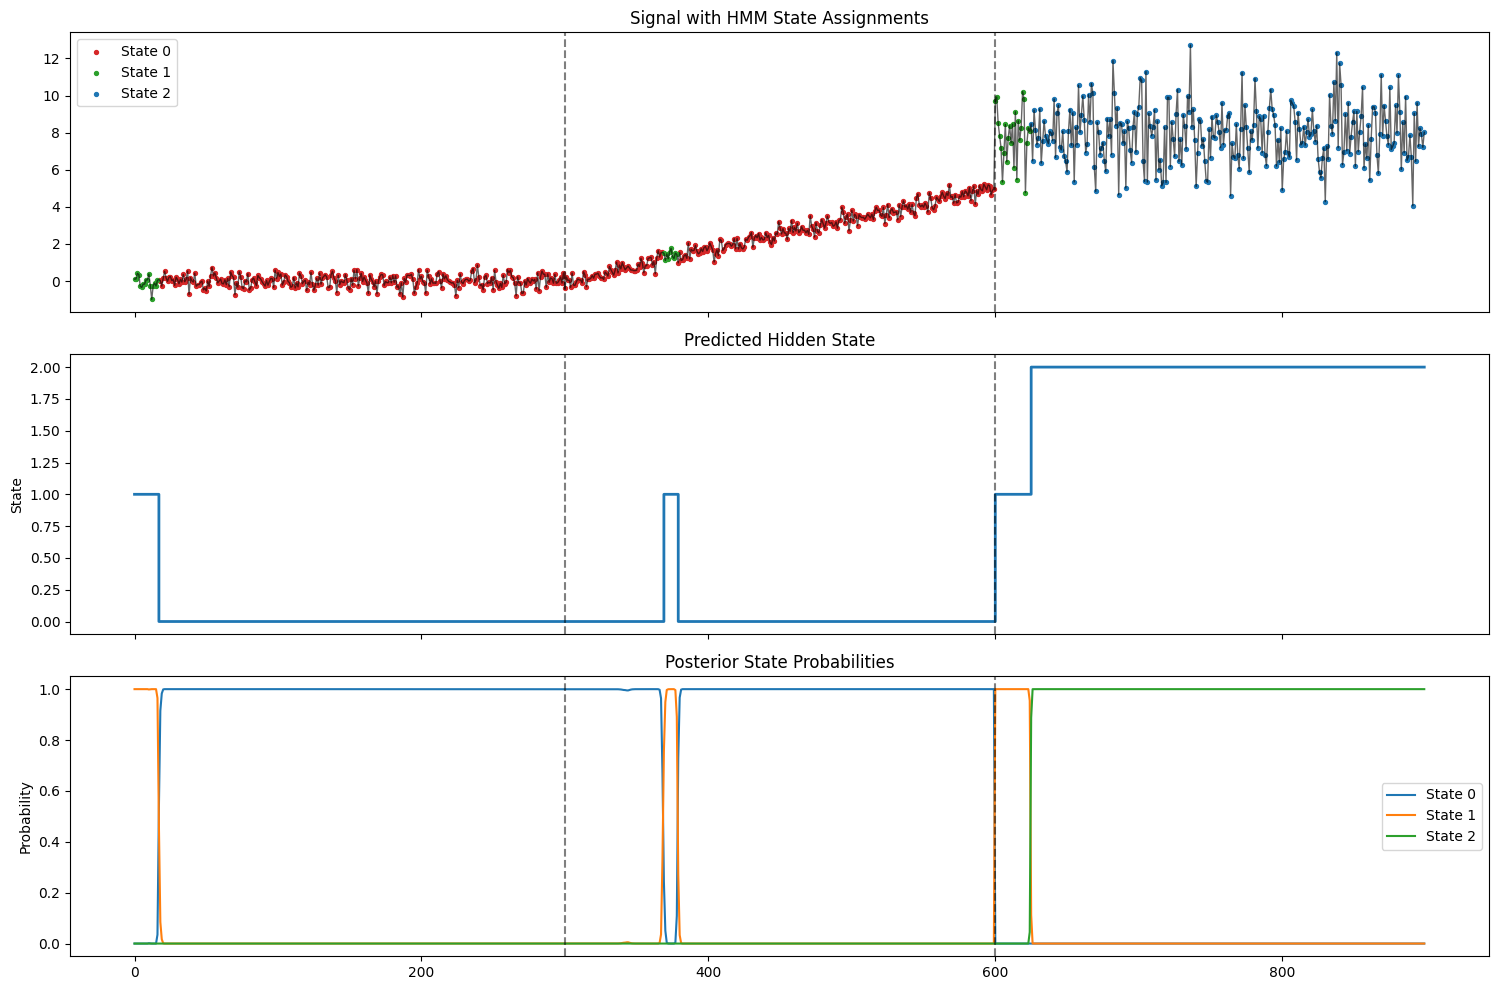

In [7]:
print("\nState statistics:\n")

for state in np.unique(states):

    vals = signal[states == state]

    print(
        f"State {state}"
    )

    print(
        f"  Mean = {vals.mean():.3f}"
    )

    print(
        f"  Std  = {vals.std():.3f}"
    )

    print(
        f"  Count= {len(vals)}"
    )

    print()


fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 10),
    sharex=True
)

colors = [
    "tab:red",
    "tab:green",
    "tab:blue",
    "tab:orange",
    "tab:purple"
]

# ----------------------------------------------------------
# Plot 1: Raw signal + state assignments
# ----------------------------------------------------------

axes[0].plot(
    signal,
    color="black",
    alpha=0.6,
    linewidth=1
)

for state in np.unique(states):

    idx = states == state

    axes[0].scatter(
        np.where(idx)[0],
        signal[idx],
        s=8,
        color=colors[state],
        label=f"State {state}"
    )

for boundary in true_boundaries:
    axes[0].axvline(
        boundary,
        color="black",
        linestyle="--",
        alpha=0.5
    )

axes[0].set_title(
    "Signal with HMM State Assignments"
)

axes[0].legend()


# ----------------------------------------------------------
# Plot 2: State sequence
# ----------------------------------------------------------

axes[1].plot(
    states,
    drawstyle="steps-post",
    linewidth=2
)

for boundary in true_boundaries:
    axes[1].axvline(
        boundary,
        color="black",
        linestyle="--",
        alpha=0.5
    )

axes[1].set_title(
    "Predicted Hidden State"
)

axes[1].set_ylabel(
    "State"
)


# ----------------------------------------------------------
# Plot 3: State probabilities
# ----------------------------------------------------------

for state in range(model.n_components):

    axes[2].plot(
        state_probs[:, state],
        label=f"State {state}"
    )

for boundary in true_boundaries:
    axes[2].axvline(
        boundary,
        color="black",
        linestyle="--",
        alpha=0.5
    )

axes[2].set_title(
    "Posterior State Probabilities"
)

axes[2].set_ylabel(
    "Probability"
)

axes[2].legend()


plt.tight_layout()
plt.show()

In [8]:
def build_window_features(segment, window=20):

    features = []

    for i in range(len(segment) - window + 1):

        x = segment[i:i+window]

        mean = np.mean(x)
        std = np.std(x)

        slope = linregress(
            np.arange(window),
            x
        ).slope

        value_range = np.max(x) - np.min(x)

        features.append([
            mean,
            std,
            slope,
            value_range
        ])

    return np.array(features)

In [9]:
window_size = 20

phase_results = []

for state, start, end in intervals:

    segment = signal[start:end+1]

    if len(segment) < window_size:
        continue

    X_phase = build_window_features(
        segment,
        window=window_size
    )

    scaler = StandardScaler()

    X_phase = scaler.fit_transform(
        X_phase
    )

    iso = IsolationForest(
        n_estimators=300,
        contamination=0.05,
        random_state=42
    )

    iso.fit(X_phase)

    anomaly_scores = -iso.score_samples(
        X_phase
    )

    threshold = np.quantile(
        anomaly_scores,
        0.95
    )

    anomaly_windows = np.where(
        anomaly_scores >= threshold
    )[0]

    anomaly_intervals = []

    for idx in anomaly_windows:

        global_start = start + idx

        global_end = (
            global_start
            + window_size
            - 1
        )

        anomaly_intervals.append(
            (
                global_start,
                global_end
            )
        )

    phase_results.append({
        "state": state,
        "start": start,
        "end": end,
        "scores": anomaly_scores,
        "anomaly_windows": anomaly_windows,
        "anomaly_intervals": anomaly_intervals
    })


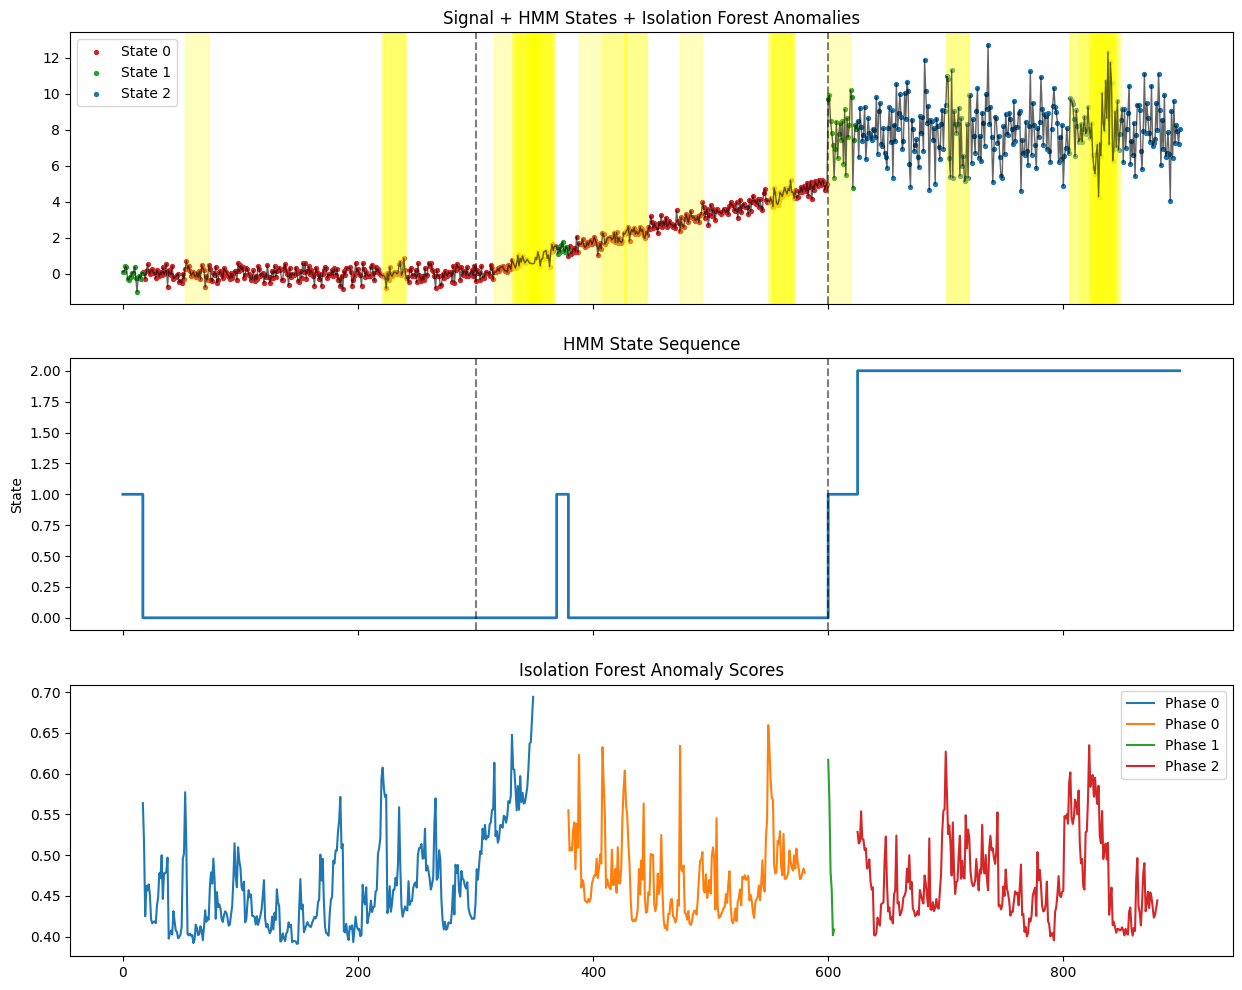

In [10]:
fig, axes = plt.subplots(
    3,
    1,
    figsize=(15, 12),
    sharex=True
)

colors = [
    "tab:red",
    "tab:green",
    "tab:blue",
    "tab:orange",
    "tab:purple"
]


axes[0].plot(
    signal,
    color="black",
    alpha=0.6,
    linewidth=1
)

for state in np.unique(states):

    idx = states == state

    axes[0].scatter(
        np.where(idx)[0],
        signal[idx],
        s=8,
        color=colors[state],
        label=f"State {state}"
    )

for result in phase_results:

    for s, e in result["anomaly_intervals"]:

        axes[0].axvspan(
            s,
            e,
            color="yellow",
            alpha=0.25
        )

for boundary in true_boundaries:

    axes[0].axvline(
        boundary,
        color="black",
        linestyle="--",
        alpha=0.5
    )

axes[0].set_title(
    "Signal + HMM States + Isolation Forest Anomalies"
)

axes[0].legend()


axes[1].plot(
    states,
    drawstyle="steps-post",
    linewidth=2
)

for boundary in true_boundaries:

    axes[1].axvline(
        boundary,
        color="black",
        linestyle="--",
        alpha=0.5
    )

axes[1].set_title(
    "HMM State Sequence"
)

axes[1].set_ylabel(
    "State"
)



for result in phase_results:

    scores = result["scores"]

    x = np.arange(
        result["start"],
        result["start"] + len(scores)
    )

    axes[2].plot(
        x,
        scores,
        label=f"Phase {result['state']}"
    )

axes[2].set_title(
    "Isolation Forest Anomaly Scores"
)

axes[2].legend()


In [11]:
anomaly_indicator = np.zeros(
    len(signal)
)

for result in phase_results:

    for s, e in result["anomaly_intervals"]:

        anomaly_indicator[s:e+1] = 1

axes[3].plot(
    anomaly_indicator,
    drawstyle="steps-post",
    linewidth=2
)

axes[3].set_title(
    "Detected Anomalous Intervals"
)

axes[3].set_ylim(
    -0.1,
    1.1
)

axes[3].set_ylabel(
    "Anomaly"
)

plt.tight_layout()
plt.show()

print("\nDetected intra-phase anomalies:\n")

for result in phase_results:

    print(
        f"\nPhase {result['state']} "
        f"({result['start']} -> {result['end']})"
    )

    for s, e in result["anomaly_intervals"]:

        print(
            f"  Anomaly: {s} -> {e}"
        )

IndexError: index 3 is out of bounds for axis 0 with size 3

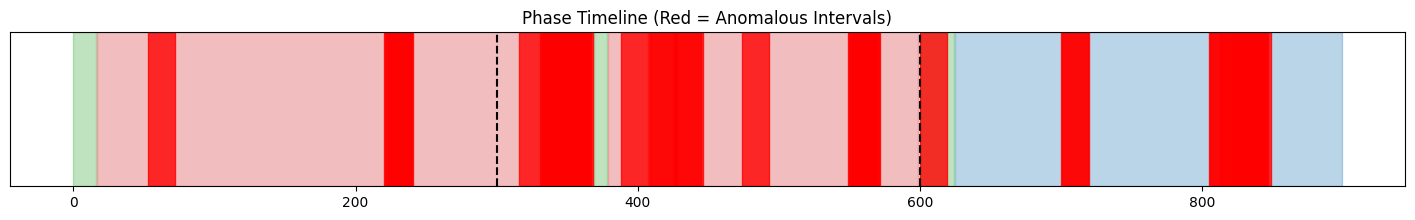

In [ ]:
fig, ax = plt.subplots(
    figsize=(18, 2)
)

for state, start, end in intervals:

    ax.axvspan(
        start,
        end,
        color=colors[state],
        alpha=0.3
    )

for result in phase_results:

    for s, e in result["anomaly_intervals"]:

        ax.axvspan(
            s,
            e,
            color="red",
            alpha=0.8
        )

for boundary in true_boundaries:

    ax.axvline(
        boundary,
        color="black",
        linestyle="--"
    )

ax.set_ylim(0, 1)
ax.set_yticks([])

ax.set_title(
    "Phase Timeline (Red = Anomalous Intervals)"
)

plt.show()